In [1]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt

from meg import Meg

run01_prefix = 'sub-01_ses-01_task-listen_run-01'
meg = Meg(run01_prefix, filter=False, maxwell=True)
raw = meg.raw_before_maxwell
flat = meg.flat_channels

/home/felipe/git/phd/meg/nbs/../meg.py:16: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(


Bad channel detection started at 2026-10-07 23:11:34.
Bad channel detection ended at 2026-10-07 23:17:19; elapsed 345.42 seconds. Noisy: ['MEG0513', 'MEG1423', 'MEG2342']; flat: ['MEG0213', 'MEG0311', 'MEG0813', 'MEG1243', 'MEG1443', 'MEG1541', 'MEG1811', 'MEG2122', 'MEG2123', 'MEG2121'].
Maxwell filtering started at 2026-10-07 23:17:19.
Maxwell filtering ended at 2026-10-07 23:17:24; elapsed 4.70 seconds.


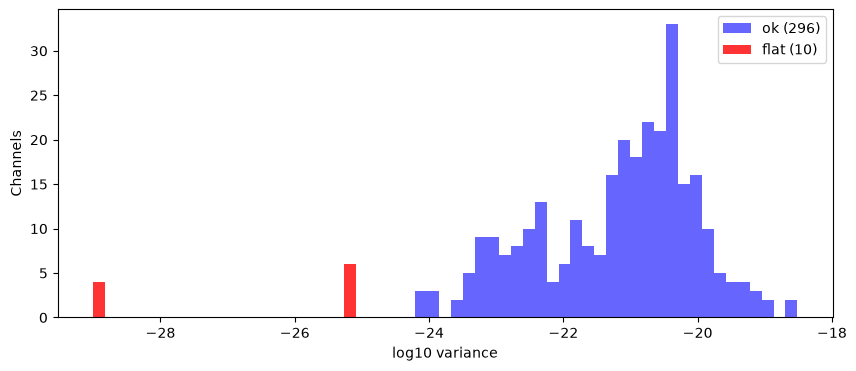

In [2]:
meg_picks = [i for i, ch in enumerate(raw.ch_names) if ch.startswith('MEG')]
meg_names = [raw.ch_names[i] for i in meg_picks]
data = raw.get_data(picks=meg_picks)
variance = data.var(axis=1)
is_flat = np.array([ch in flat for ch in meg_names])

# Magnetometers (T) and gradiometers (T/m) have different scales, so log-variance is used
log_var = np.log10(variance)
bins = np.linspace(log_var.min(), log_var.max(), 60)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(log_var[~is_flat], bins=bins, color='blue', alpha=0.6, label=f'ok ({(~is_flat).sum()})')
ax.hist(log_var[is_flat], bins=bins, color='red', alpha=0.8, label=f'flat ({is_flat.sum()})')
ax.set_xlabel('log10 variance')
ax.set_ylabel('Channels')
ax.legend()
plt.show()

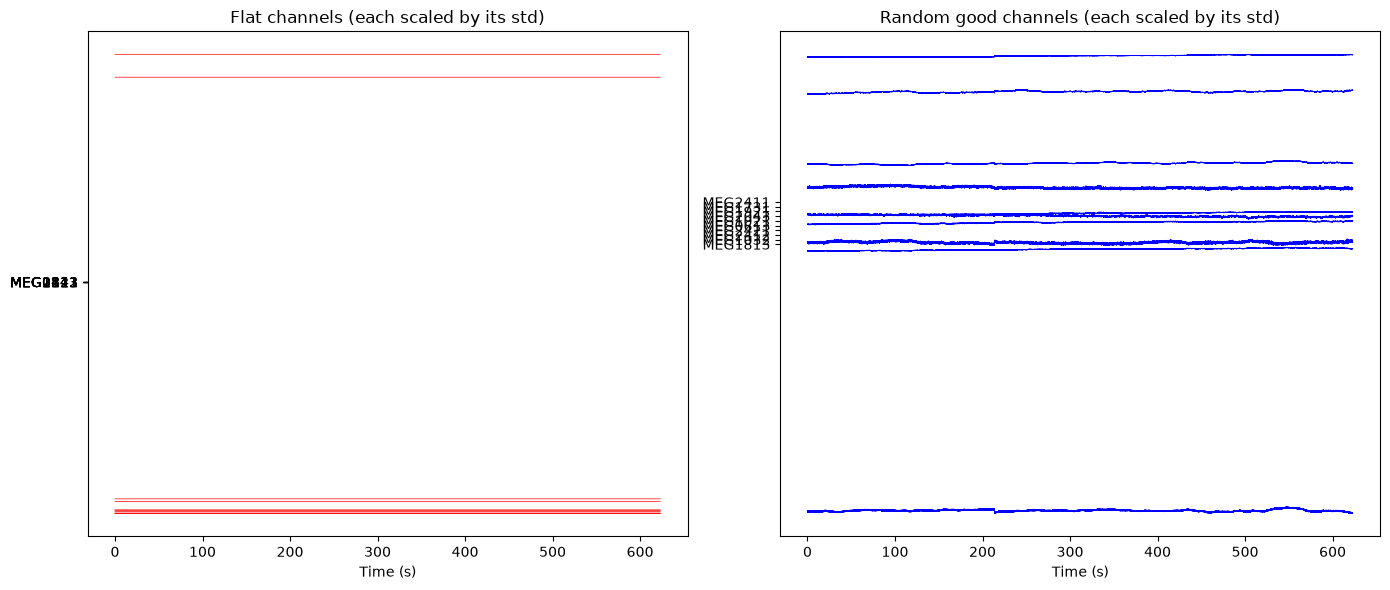

In [3]:
rng = np.random.default_rng()
good_idx = rng.choice(np.flatnonzero(~is_flat), size=len(flat), replace=False)
flat_idx = np.flatnonzero(is_flat)
times = raw.times

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, idx, color, title in [(axes[0], flat_idx, 'red', 'Flat channels'),
                              (axes[1], good_idx, 'blue', 'Random good channels')]:
    for k, i in enumerate(idx):
        ax.plot(times, data[i] / data[i].std() + 5 * k, color=color, linewidth=0.5)
    ax.set_yticks(5 * np.arange(len(idx)))
    ax.set_yticklabels([meg_names[i] for i in idx])
    ax.set_xlabel('Time (s)')
    ax.set_title(title + ' (each scaled by its std)')
plt.tight_layout()
plt.show()